# 06. 승패 모델 후보 넓히기 — 랜덤포레스트·XGBoost까지 튜닝해 보기

안녕하세요! **KBO 승패 예측 프로젝트의 여섯 번째 이야기**예요. 짝이 되는 코드는 `src/kbo_predict/tune.py`예요.

**이 노트북이 하는 일**
- 03번 노트북(그때의 v0.2)에서는 로지스틱 회귀와 LightGBM 두 개만 비교해 로지스틱 회귀(C=1)를 골랐어요.
- 여기서는 후보를 **6계열**(로지스틱 회귀, 랜덤포레스트, 엑스트라 트리, sklearn 히스토그램 부스팅, LightGBM, XGBoost)로 넓히고,
  계열마다 설정을 여러 개 뽑아(랜덤 서치) 가장 좋은 것을 찾아요.
- 전체 탐색(설정 214개 × 5시즌 교차검증)은 15분쯤 걸려서 `python -m kbo_predict.tune`으로 미리 돌려 두었어요.
  이 노트북은 그 결과 파일(`data/public/tuning_report.json`)을 읽어 보여 주고, **결승 단계는 여기서 다시 계산해서**
  스크립트와 숫자가 똑같은지 확인해요.

**왜 이렇게 나누나요?**
- 설정을 수십 개 비교하면, 한 시즌(약 700경기)만으로 고를 때 "그 시즌에 운 좋게 맞은 설정"이 뽑히기 쉬워요.
  그래서 튜닝 점수는 **2021~2025 다섯 시즌**을 각각 "그 앞 시즌 전부로 학습 → 그 시즌 예측"해서 매겨요(약 3,500경기).
- **2026 시즌(시험)은 고르는 데 한 번도 쓰지 않아요.** 03번과 같은 약속이에요. 고른 뒤에 채점만 해요.

> **읽기 전에 (2026-11 덧붙임):** 이 노트북에서 **"지금 모델"**은 이 튜닝을 할 때의 라이브 모델 **v0.2**(로지스틱 회귀 L2, C = 1, 피처 26개, Platt 보정)를 뜻해요. 분석 내용은 그대로 맞아요. 다만 그 뒤 08번 노트북의 **여러 시즌 시험**을 근거로 모델을 **v0.3**(로지스틱 회귀 L1, C = 0.03 + Elo 피처)으로 바꿨어요. 자세한 이야기는 맨 끝에 적어 뒀어요.

## 1. 준비

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위가 프로젝트 루트예요. `src/`를 파이썬 경로에 넣어 `kbo_predict`를 불러와요.
- 랜덤포레스트가 CPU 코어 수를 찾다가 내는 안내 메시지를 막으려고 `LOKY_MAX_CPU_COUNT`를 먼저 정해요(결과에는 영향이 없어요).
- 02번 노트북이 만든 피처 표와 튜닝 결과 파일을 읽어요.

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")          # scikit-learn이 코어 수를 찾다 내는 경고를 막아요
warnings.filterwarnings("ignore")                          # 라이브러리 버전 안내 메시지는 숨겨요 (계산에는 영향 없음)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

T0 = time.time()
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from kbo_predict import tune
from kbo_predict.features import FACTOR_LABELS, FEATURE_NAMES, load_features

plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요

df = load_features(ROOT / "data" / "processed" / "features.parquet")
report = json.loads((ROOT / "data" / "public" / "tuning_report.json").read_text(encoding="utf-8"))
print(f"피처 표 {len(df):,}경기 × 피처 {len(FEATURE_NAMES)}개, 시즌 {df.season.min()}~{df.season.max()}")
print("튜닝 결과 파일 만든 시각:", report["generated_at"], "/ 탐색에 걸린 시간:", report["elapsed_sec"], "초")

피처 표 8,465경기 × 피처 26개, 시즌 2015~2026
튜닝 결과 파일 만든 시각: 2026-11-03T08:21:41+09:00 / 탐색에 걸린 시간: 887.9 초


## 2. 무엇을 얼마나 찾아봤나

계열마다 "값 후보 목록"을 정해 두고, 그중에서 고정 시드로 40개 설정을 뽑았어요(로지스틱 회귀는 조합이 14개뿐이라 전부).
같은 시드면 언제 돌려도 같은 설정이 뽑혀요.

In [2]:
space = pd.DataFrame([
    {"계열": tune.FAMILY_KO[f], "찾아본 설정 수": report["n_configs"][f],
     "튜닝한 값": ", ".join(f"{k} {v}" for k, v in tune.SPACE[f].items())}
    for f in tune.FAMILIES
])
pd.set_option("display.max_colwidth", 200)
display(space)

,계열,찾아본 설정 수,튜닝한 값
0,로지스틱 회귀,14,"C [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0], penalty ['l2', 'l1']"
1,랜덤포레스트,40,"n_estimators [300, 600], max_depth [4, 6, 8, 12, None], min_samples_leaf [10, 20, 50, 100], max_features ['sqrt', 0.3, 0.5]"
2,엑스트라 트리,40,"n_estimators [300, 600], max_depth [4, 6, 8, 12, None], min_samples_leaf [10, 20, 50, 100], max_features ['sqrt', 0.3, 0.5]"
3,히스토그램 부스팅(sklearn),40,"learning_rate [0.02, 0.05, 0.1], max_iter [100, 200, 400], max_depth [2, 3, 4, None], min_samples_leaf [20, 50, 100], l2_regularization [0.0, 1.0, 10.0]"
4,LightGBM,40,"learning_rate [0.01, 0.03, 0.05], n_estimators [100, 200, 400, 800], num_leaves [4, 7, 15, 31], min_child_samples [20, 50, 100], colsample_bytree [0.5, 0.8, 1.0], reg_lambda [0.0, 1.0, 10.0]"
5,XGBoost,40,"learning_rate [0.01, 0.03, 0.05], n_estimators [100, 200, 400, 800], max_depth [2, 3, 4, 6], min_child_weight [1, 5, 20], subsample [0.7, 1.0], colsample_bytree [0.5, 0.8, 1.0], reg_lambda [1.0, 1..."


## 3. 1단계 — 계열별 교차검증 순위

점수는 **log loss**(낮을수록 좋음)예요. 확률이 실제 결과와 얼마나 가까운지를 재요. 정확도는 참고로 함께 적어요.
아래는 계열마다 가장 좋았던 설정이에요. 지금 모델(로지스틱 회귀 C=1)도 같은 방식으로 재 보면 0.6832로, 여섯 계열 1등 모두보다 높아요(나빠요).

In [3]:
best = pd.DataFrame([
    {"계열": tune.FAMILY_KO[f], "CV log loss": rows[0]["log_loss"], "CV 정확도": rows[0]["accuracy"],
     **{f"{s}시즌": rows[0]["per_season_log_loss"][str(s)] for s in tune.CV_SEASONS}, "가장 좋은 설정": rows[0]["params"]}
    for f, rows in report["search"].items()
]).sort_values("CV log loss")
display(best.style.format({c: "{:.4f}" for c in best.columns if c not in ("계열", "가장 좋은 설정")}).hide(axis="index"))

cur_cv = tune.cv_score(*tune.CURRENT, df)
print(f"지금 모델(로지스틱 회귀 C=1) CV log loss {cur_cv['log_loss']:.4f}, 정확도 {cur_cv['accuracy']:.1%}")

계열,CV log loss,CV 정확도,2021시즌,2022시즌,2023시즌,2024시즌,2025시즌,가장 좋은 설정
랜덤포레스트,0.6792,0.5693,0.6805,0.6774,0.6786,0.6812,0.6786,"{'n_estimators': 600, 'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 'sqrt'}"
로지스틱 회귀,0.6793,0.5696,0.6812,0.6812,0.6786,0.6808,0.6747,"{'C': 0.03, 'penalty': 'l1'}"
XGBoost,0.6796,0.5673,0.6811,0.6802,0.6766,0.6831,0.6770,"{'learning_rate': 0.03, 'n_estimators': 100, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 1.0}"
엑스트라 트리,0.6808,0.5624,0.6814,0.6816,0.6791,0.6820,0.6798,"{'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 20, 'max_features': 0.5}"
LightGBM,0.6808,0.5627,0.6839,0.6804,0.6793,0.6820,0.6786,"{'learning_rate': 0.01, 'n_estimators': 200, 'num_leaves': 7, 'min_child_samples': 20, 'colsample_bytree': 0.5, 'reg_lambda': 10.0}"
히스토그램 부스팅(sklearn),0.6810,0.5587,0.6803,0.6804,0.6830,0.6810,0.6802,"{'learning_rate': 0.02, 'max_iter': 200, 'max_depth': 3, 'min_samples_leaf': 20, 'l2_regularization': 1.0}"


지금 모델(로지스틱 회귀 C=1) CV log loss 0.6832, 정확도 56.2%


## 4. 2단계 — 결승: 성적표와 똑같은 절차로 다시 겨루기

계열별 1등 여섯 개만 남겨, 03번 노트북의 성적표와 **똑같은 절차**로 다시 겨뤄요.
1. 2015~2024로 학습해요.
2. 확률 보정 방법(없음 / Platt / isotonic)은 학습 시즌 "한 시즌씩 빼고 학습해 그 시즌 예측"한 값으로 맞추고, 2025 검증으로 골라요.
3. **2025 검증 log loss가 가장 낮은 것이 추천 모델**이에요.
4. 2026 시험 점수는 고른 뒤에 채점한 거예요. 시험에서 지금 모델과 경기별 적중이 정말 다른지 McNemar 검정 p값도 적어요.

여기서는 결승을 **다시 계산**해서 결과 파일의 숫자와 같은지 확인해요(1~2분 걸려요).

In [4]:
rerun = {f["family"]: tune.final_round(f["family"], f["params"], df) for f in report["finalists"]}
rerun_current = tune.final_round(*tune.CURRENT, df)

same = all(
    abs(rerun[f["family"]][part]["log_loss"] - f[part]["log_loss"]) < 1e-12
    and abs(rerun[f["family"]][part]["accuracy"] - f[part]["accuracy"]) < 1e-12
    for f in report["finalists"] for part in ("val", "test")
) and abs(rerun_current["val"]["log_loss"] - report["current"]["val"]["log_loss"]) < 1e-12
print("노트북에서 다시 계산한 결승 숫자가 스크립트 결과와 같나요?", "같아요" if same else "달라요")

rows = [("지금 모델", report["current"])] + [(tune.FAMILY_KO[f["family"]], f) for f in report["finalists"]]
final = pd.DataFrame([
    {"모델": name, "보정": f["calibration"], "2025 검증 log loss": f["val"]["log_loss"], "2025 검증 정확도": f["val"]["accuracy"],
     "2026 시험 log loss": f["test"]["log_loss"], "2026 시험 정확도": f["test"]["accuracy"], "2026 Brier": f["test"]["brier"],
     "지금 모델 대비 p값": f["mcnemar_p_vs_current"]}
    for name, f in rows
])
display(final.style.format({c: "{:.4f}" for c in final.columns if c not in ("모델", "보정")}).hide(axis="index"))

노트북에서 다시 계산한 결승 숫자가 스크립트 결과와 같나요? 같아요


모델,보정,2025 검증 log loss,2025 검증 정확도,2026 시험 log loss,2026 시험 정확도,2026 Brier,지금 모델 대비 p값
지금 모델,platt,0.6771,0.5731,0.6712,0.5940,0.2393,1.0000
로지스틱 회귀,none,0.6747,0.5817,0.6695,0.6083,0.2384,0.1641
LightGBM,isotonic,0.6755,0.5774,0.6712,0.5954,0.2392,1.0000
랜덤포레스트,isotonic,0.6764,0.5917,0.6705,0.5897,0.2376,0.8522
XGBoost,platt,0.6769,0.5917,0.6692,0.5869,0.2383,0.6752
엑스트라 트리,none,0.6798,0.5774,0.6706,0.5883,0.2389,0.7688
히스토그램 부스팅(sklearn),platt,0.6799,0.5659,0.6743,0.5812,0.2407,0.4069


## 5. 그림으로 보기 — 검증과 시험에서 모두 낮을수록 좋아요

왼쪽 막대는 고르는 데 쓴 2025 검증, 오른쪽은 고른 뒤 채점한 2026 시험이에요. 회색 점선은 지금 모델이에요.

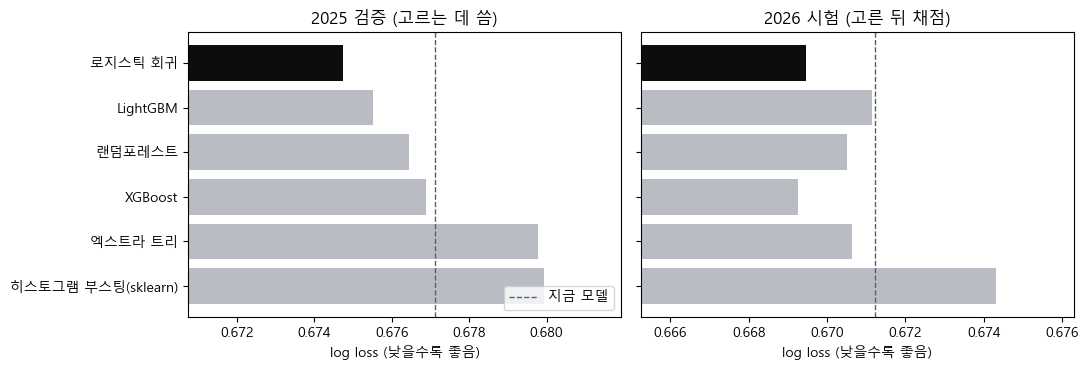

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
names = [tune.FAMILY_KO[f["family"]] for f in report["finalists"]]
for ax, part, title in zip(axes, ("val", "test"), ("2025 검증 (고르는 데 씀)", "2026 시험 (고른 뒤 채점)")):
    vals = [f[part]["log_loss"] for f in report["finalists"]]
    colors = ["#0d0d0f" if i == 0 else "#b9bcc3" for i in range(len(vals))]
    ax.barh(names[::-1], vals[::-1], color=colors[::-1])
    ax.axvline(report["current"][part]["log_loss"], color="#5a5e66", linestyle="--", linewidth=1, label="지금 모델")
    ax.set_xlim(min(vals) - 0.004, max(vals) + 0.002)
    ax.set_title(title)
    ax.set_xlabel("log loss (낮을수록 좋음)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. 추천 모델은 무엇을 남겼나

추천 모델은 **L1 규제를 세게 건 로지스틱 회귀(C=0.03)**예요. L1은 쓸모가 적은 피처의 계수를 0으로 만들어 없애요.
피처 26개 중 몇 개가 살아남았는지, 계수(표준화한 피처 1 만큼 차이날 때 로짓 변화)를 볼게요. +는 홈팀에 유리한 방향이에요.

In [6]:
rec = report["recommended"]
train = df[df.season.isin(tune.TRAIN_SEASONS)]
model = tune.make_estimator(rec["family"], rec["params"]).fit(train[FEATURE_NAMES].astype(float), train["y"])
coef = pd.Series(model.named_steps["clf"].coef_[0], index=[FACTOR_LABELS.get(n, n) for n in FEATURE_NAMES])
kept = coef[coef.abs() > 1e-9].sort_values(key=abs, ascending=False)
print(f"살아남은 피처 {len(kept)}개 / {len(coef)}개")
display(kept.round(3).to_frame("계수"))
print("빠진 피처:", ", ".join(coef[coef.abs() <= 1e-9].index))

살아남은 피처 12개 / 26개


,계수
선발 FIP 차이,-0.121
선발 9이닝당 삼진 차이,0.096
지난 시즌 승률 차이,0.089
선발 누적 이닝 차이,0.078
타선 삼진 비율 차이,-0.068
선발 9이닝당 볼넷 차이,-0.066
타선 홈런 비율 차이,0.063
팀 승률 차이,0.051
휴식일 차이,0.035
최근 3일 불펜 투구수 차이,-0.020


빠진 피처: 최근 10경기 흐름, 경기당 득실차, 피타고리안 기대 승률 차이, 타선 출루율 차이, 타선 볼넷 비율 차이, 투수진 평균자책점 차이, 투수진 FIP 차이, 투수진 9이닝당 삼진 차이, 투수진 9이닝당 볼넷 차이, 홈팀의 홈 경기 승률, 올 시즌 맞대결 승률, 선발투수 기록 유무, 선발 평균자책점 차이, 선발 최근 3경기 실점 차이


## 7. 정리

- **추천**: 로지스틱 회귀 L1, C=0.03, 보정 없음. 2025 검증 log loss가 지금 모델보다 0.0024 낮아 채택 기준(0.002)을 겨우 넘었어요.
- **2026 시험**(고른 뒤 채점): 정확도 59.4% → 60.8%, log loss 0.6712 → 0.6695로 조금 좋아졌어요.
  하지만 지금 모델과 경기별 적중을 비교한 p값은 0.16으로, **차이가 우연이 아니라고 말할 수는 없어요.**
- **트리 모델(랜덤포레스트·XGBoost·LightGBM)**은 튜닝해도 로지스틱 회귀를 넘지 못했어요. 피처가 이미 "차이" 형태로 잘 정리돼 있고
  경기 수(한 해 약 700경기)가 많지 않아, 복잡한 모델이 더 배울 패턴이 적다는 뜻으로 읽을 수 있어요.
- 쓸모 있는 피처가 12개로 줄어 **더 단순한 모델이 같거나 조금 나은 성적**을 냈어요. 설명하기도 더 쉬워요.
- 이 노트북을 만들 때는 라이브 모델(v0.2)과 성적표(report-2026)를 바로 바꾸지 않았어요. 한 시즌(2026)으로는 차이가 우연인지 알 수 없었고, 바꾸면 성적표·되감기 165일을 다시 만들어야 했거든요. 그 결정은 아래 8번처럼 여러 시즌으로 확인한 뒤에 했어요.

## 8. 그 뒤 이야기 — 여러 시즌으로 확인하고 v0.3으로 바꿨어요 (08번)

여기서 추천한 **L1 로지스틱 회귀(C = 0.03)**가 정말 v0.2보다 나은지, 2026 한 시즌(702경기)으로는 가릴 수 없었어요(p = 0.16).
그래서 08번 노트북에서 **여러 시즌 시험**을 했어요. 2018~2026 시즌마다 "그 앞 시즌들로만 학습 → 그 시즌 예측"을 되풀이해 **6,328경기**로 다시 잰 거예요. 후보와 고르는 규칙은 계산 전에 정해 뒀어요.
- 후보: v0.2 설정(L2, C = 1), 이 노트북의 추천(L1, C = 0.03), **L1 + Elo 전력 점수**, 앙상블(L1 + 랜덤포레스트 + XGBoost).
- 고르는 규칙: 개발 시즌 2018~2025의 합친 log loss가 가장 낮은 후보.
- 결과: **L1 + Elo**가 뽑혔어요. 2018~2026 정확도 57.9%로 v0.2 설정(56.5%)보다 유의하게 나았어요(p = 0.001). 이 노트북의 추천(L1만)도 57.4%로 v0.2 설정보다 나았어요(p = 0.011).

그래서 지금 모델은 **v0.3 = L1, C = 0.03 + Elo 피처(피처 27개), 보정 없음**이에요(2026 시험 61.0%). 위의 분석은 "v0.2 시절, 피처 26개로 한 튜닝"으로 읽어 주세요.
한 가지 정직하게 적어 둘 점: 이 노트북의 설정 선택에 2021~2025 교차검증을 썼기 때문에, 08번에서 그 시즌들의 L1 성적은 조금 유리하게 나와요. 08번은 그래서 설정 선택에 쓰지 않은 시즌(2018~2020, 2026)만 모은 성적도 따로 보여 줘요.

In [7]:
print(f"노트북 실행 시간: {time.time() - T0:.0f}초")

노트북 실행 시간: 47초
